# Supplementary Figure S15 — vapor bubbles

Standalone, function-free workflow for the three-panel vapor-bubble figure. The scientific filtering, stored Raman fields, analytical-zero treatment, and highlighted melt inclusions are unchanged.

## Shared setup for Figure S15

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle
from matplotlib.path import Path as MarkerPath
from IPython.display import display

DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S15_Vapor_Bubbles'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S15_Vapor_Bubbles_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

WORKBOOK_PATHS = {
    'S1': DATA_DIRECTORY / 'Dechert_S1_AllData.xlsx',
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
FIGURE_WIDTH_IN = SINGLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 7.2
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300

PUBLICATION_FONT = 'Arial'
if PUBLICATION_FONT not in {entry.name for entry in font_manager.fontManager.ttflist}:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)

mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT, 'axes.labelsize': BASE_TEXT_SIZE_PT,
    'axes.titlesize': BASE_TEXT_SIZE_PT, 'xtick.labelsize': BASE_TEXT_SIZE_PT,
    'ytick.labelsize': BASE_TEXT_SIZE_PT, 'legend.fontsize': BASE_TEXT_SIZE_PT,
    'legend.title_fontsize': BASE_TEXT_SIZE_PT,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': True, 'axes.spines.right': True, 'axes.linewidth': 0.5,
    'lines.linewidth': 0.75, 'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'savefig.facecolor': 'white', 'savefig.transparent': False,
    'mathtext.fontset': 'custom', 'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic', 'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
PHASE_LABELS = {'plag': 'Plagioclase-hosted MI', 'pxy': 'Pyroxene-hosted MI'}

# Approved marker geometry from 00_Setup.
MARKER_SPANS_PT = {'plag': 6.0, 'pxy': 6.0}
MARKER_LETTERS = {'plag': 'o', 'pxy': 's'}
MARKER_PATHS = {}
SCATTER_STYLES = {}
for category, marker in MARKER_LETTERS.items():
    standard_marker = MarkerStyle(marker)
    marker_path = standard_marker.get_path().transformed(standard_marker.get_transform())
    bounds = marker_path.get_extents()
    vertices = marker_path.vertices.copy()
    vertices[:, 0] = (vertices[:, 0] - (bounds.x0 + bounds.x1) / 2) / bounds.width
    vertices[:, 1] = (vertices[:, 1] - (bounds.y0 + bounds.y1) / 2) / bounds.height
    normalized_path = MarkerPath(vertices, marker_path.codes)
    MARKER_PATHS[category] = normalized_path
    SCATTER_STYLES[category] = {
        'marker': normalized_path,
        's': (MARKER_SPANS_PT[category] - MINIMUM_LINE_WIDTH_PT) ** 2,
        'linewidths': MINIMUM_LINE_WIDTH_PT,
        'edgecolors': 'black',
    }

print('Figure directory:', FIGURE_DIRECTORY)
print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure dimensions:', FIGURE_WIDTH_IN, 'x', FIGURE_HEIGHT_IN, 'in')

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S15_Vapor_Bubbles
Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 3.55 x 7.2 in


## Figure S15-specific data preparation

The shared setup ends above. This figure reads only Supplement 1, sheet `MI_Hosts_Plag_Pxy`. Matrix-glass rows, rows flagged `Discard_SIMS == yes`, and unsupported sample or host categories are excluded. Panels A and C use the stored values for each numbered vapor bubble. Panel B retains the established analytical-zero treatment only for inclusions explicitly measured by Raman but lacking a quantifiable diad.

In [2]:
source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Hosts_Plag_Pxy')

TOTAL_CO2_COLUMN = 'Total_CO2_ppm_final'
VB_TOTAL_CO2_COLUMN = 'VB_MI_Total_CO2_RecalcDensityX_Raman'
SIMS_CO2_COLUMN = 'CO2 ppm_SIMS'
RAMAN_FLAG_COLUMN = 'VB_Ramaned_Raman'
N_HIGHEST_CO2_MIS = 5

bubble_co2_columns = [f'VB{number}_CO2_ppm_RecalcDensityX_Raman' for number in range(1, 5)]
bubble_density_columns = [f'VB{number}_Density g/cm3_Raman' for number in range(1, 5)]
bubble_volume_columns = [f'VB{number}_Volume VB um3_Raman' for number in range(1, 5)]
mi_volume_columns = [f'VB{number}_Volume MI um3_Raman' for number in range(1, 5)]

numeric_columns = [
    TOTAL_CO2_COLUMN,
    VB_TOTAL_CO2_COLUMN,
    SIMS_CO2_COLUMN,
    *bubble_co2_columns,
    *bubble_density_columns,
    *bubble_volume_columns,
    *mi_volume_columns,
]

data = source.copy()
data['sample_key'] = np.select(
    [
        data['base_name'].astype('string').str.startswith('74D'),
        data['base_name'].astype('string').str.startswith('74A'),
        data['base_name'].astype('string').str.startswith('75'),
        data['base_name'].astype('string').str.startswith('76A'),
    ],
    ['74D', '74A', '75', '76A'],
    default='unmapped',
)
data['phase_key'] = data['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx': 'pxy'})
data['matrix_glass'] = data['base_name'].astype('string').str.contains('MTX', case=False, na=False)
data['discard_sims'] = data['Discard_SIMS'].astype('string').str.strip().str.casefold().eq('yes').fillna(False)
data['raman_measured'] = data[RAMAN_FLAG_COLUMN].astype('string').str.strip().str.casefold().eq('yes').fillna(False)

for column in numeric_columns:
    data[column] = pd.to_numeric(data[column], errors='coerce').replace([np.inf, -np.inf], np.nan)

eligible_rows = (
    ~data['matrix_glass']
    & ~data['discard_sims']
    & data['sample_key'].isin(SAMPLE_COLORS)
    & data['phase_key'].isin(['plag', 'pxy'])
)
eligible_mi = data.loc[eligible_rows].copy()

# Panels A and C: one row for every numbered bubble with positive stored density and volumes.
bubble_rows = []
for source_row, row in eligible_mi.iterrows():
    for bubble_number in range(1, 5):
        co2_contribution = row[f'VB{bubble_number}_CO2_ppm_RecalcDensityX_Raman']
        density = row[f'VB{bubble_number}_Density g/cm3_Raman']
        bubble_volume = row[f'VB{bubble_number}_Volume VB um3_Raman']
        mi_volume = row[f'VB{bubble_number}_Volume MI um3_Raman']

        valid_panel_a = (
            np.isfinite(co2_contribution)
            and np.isfinite(density)
            and co2_contribution > 0
            and density > 0
        )
        valid_panel_c = (
            np.isfinite(density)
            and np.isfinite(bubble_volume)
            and np.isfinite(mi_volume)
            and density > 0
            and bubble_volume > 0
            and mi_volume > 0
        )

        bubble_rows.append({
            'source_row': source_row + 2,
            'base_name': row['base_name'],
            'sample_key': row['sample_key'],
            'phase_key': row['phase_key'],
            'bubble_number': bubble_number,
            'co2_contribution_ppm': co2_contribution,
            'co2_density_g_cm3': density,
            'bubble_volume_um3': bubble_volume,
            'mi_volume_um3': mi_volume,
            'vapor_bubble_volume_percent': 100 * bubble_volume / mi_volume if valid_panel_c else np.nan,
            TOTAL_CO2_COLUMN: row[TOTAL_CO2_COLUMN],
            'has_sims_co2': bool(np.isfinite(row[SIMS_CO2_COLUMN]) and row[SIMS_CO2_COLUMN] > 0),
            'valid_panel_a': valid_panel_a,
            'valid_panel_c': valid_panel_c,
        })

all_bubble_slots = pd.DataFrame(bubble_rows)
panel_a = all_bubble_slots.loc[all_bubble_slots['valid_panel_a']].copy()
panel_c = all_bubble_slots.loc[all_bubble_slots['valid_panel_c']].copy()

# Panel B: retain Raman-measured MIs with a positive final total CO2 value.
panel_b = eligible_mi.loc[
    eligible_mi['raman_measured']
    & eligible_mi[TOTAL_CO2_COLUMN].gt(0),
    ['base_name', 'sample_key', 'phase_key', TOTAL_CO2_COLUMN, VB_TOTAL_CO2_COLUMN],
].copy()
panel_b['VB_CO2_for_plot_ppm'] = panel_b[VB_TOTAL_CO2_COLUMN].fillna(0)
panel_b['VB_CO2_percent_of_total'] = (
    100 * panel_b['VB_CO2_for_plot_ppm'] / panel_b[TOTAL_CO2_COLUMN]
)

# Highlight every valid bubble from the five plotted parent MIs with the highest final total CO2.
parent_co2 = (
    panel_c.loc[panel_c[TOTAL_CO2_COLUMN].notna()]
    .groupby('base_name', as_index=False)[TOTAL_CO2_COLUMN]
    .first()
    .sort_values([TOTAL_CO2_COLUMN, 'base_name'], ascending=[False, True], kind='stable')
)
highest_co2_mis = parent_co2.head(N_HIGHEST_CO2_MIS)
highest_co2_names = highest_co2_mis['base_name'].tolist()
panel_c['highest_CO2_MI'] = panel_c['base_name'].isin(highest_co2_names)

population_summary = pd.DataFrame({
    'population': [
        'Eligible melt inclusions',
        'Panel A bubbles',
        'Panel A parent MIs',
        'Panel B Raman-measured MIs',
        'Panel B quantified VB CO2',
        'Panel B analytical zeros',
        'Panel C bubbles',
        'Panel C parent MIs',
        'Panel C SIMS-measured bubbles',
        'Panel C Raman-only bubbles',
    ],
    'count': [
        len(eligible_mi),
        len(panel_a),
        panel_a['base_name'].nunique(),
        len(panel_b),
        panel_b[VB_TOTAL_CO2_COLUMN].notna().sum(),
        panel_b['VB_CO2_for_plot_ppm'].eq(0).sum(),
        len(panel_c),
        panel_c['base_name'].nunique(),
        panel_c['has_sims_co2'].sum(),
        (~panel_c['has_sims_co2']).sum(),
    ],
})
display(population_summary)
print('Five highlighted parent MIs:', highest_co2_names)

expected_counts = [186, 35, 24, 40, 10, 30, 35, 24, 12, 23]
if population_summary['count'].astype(int).tolist() != expected_counts:
    raise ValueError('The retained Figure S15 population has changed; review the filtering before plotting.')

expected_highest_co2_names = ['74D_C43_MI3', '76A_C28_MI2', '74D_C43_MI1', '74A_C5_MI1', '75_C21_MI1']
if highest_co2_names != expected_highest_co2_names:
    raise ValueError('The five highlighted high-CO2 parent MIs have changed; review the ranking.')

,population,count
0,Eligible melt inclusions,186
1,Panel A bubbles,35
2,Panel A parent MIs,24
3,Panel B Raman-measured MIs,40
4,Panel B quantified VB CO2,10
5,Panel B analytical zeros,30
6,Panel C bubbles,35
7,Panel C parent MIs,24
8,Panel C SIMS-measured bubbles,12
9,Panel C Raman-only bubbles,23


Five highlighted parent MIs: ['74D_C43_MI3', '76A_C28_MI2', '74D_C43_MI1', '74A_C5_MI1', '75_C21_MI1']


## Plot and export Figure S15

findfont: Failed to find font weight normal, now using 0.


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S15_Vapor_Bubbles/Figure_S15_Vapor_Bubbles_Final/Figure_S15_Vapor_Bubble_CO2_Plots.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S15_Vapor_Bubbles/Figure_S15_Vapor_Bubbles_Final/Figure_S15_Vapor_Bubble_CO2_Plots.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S15_Vapor_Bubbles/Figure_S15_Vapor_Bubbles_Final/Figure_S15_Vapor_Bubble_CO2_Plots.svg


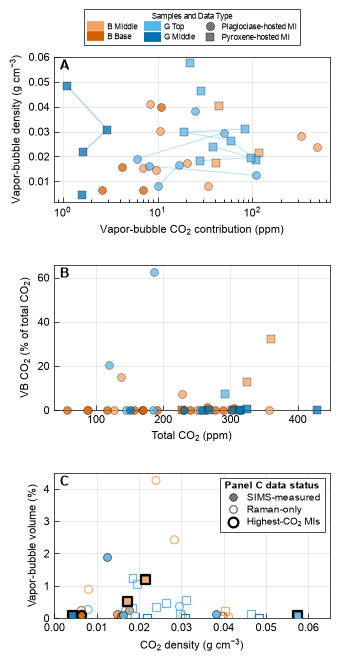

In [3]:
figure, axes = plt.subplots(3, 1, figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN))
axis_a, axis_b, axis_c = axes
PANEL_LETTERS = ['A', 'B', 'C']

# Panel A: bubble CO2 contribution versus stored Raman bubble density.
for base_name, group in panel_a.groupby('base_name', sort=False):
    ordered_group = group.sort_values('bubble_number')
    if len(ordered_group) > 1:
        sample_key = ordered_group['sample_key'].iloc[0]
        axis_a.plot(
            ordered_group['co2_contribution_ppm'],
            ordered_group['co2_density_g_cm3'],
            color=SAMPLE_COLORS[sample_key],
            linewidth=0.75,
            alpha=0.40,
            zorder=2,
        )

for sample_key, color in SAMPLE_COLORS.items():
    for phase in ['plag', 'pxy']:
        subset = panel_a.loc[
            panel_a['sample_key'].eq(sample_key)
            & panel_a['phase_key'].eq(phase)
        ]
        axis_a.scatter(
            subset['co2_contribution_ppm'],
            subset['co2_density_g_cm3'],
            facecolor=color,
            alpha=0.75,
            zorder=3,
            **SCATTER_STYLES[phase],
        )

axis_a.set_xscale('log')
axis_a.set_xlabel('Vapor-bubble CO$_2$ contribution (ppm)')
axis_a.set_ylabel('Vapor-bubble density (g cm$^{-3}$)')

# Panel B: vapor-bubble contribution as a percentage of final total CO2.
for sample_key, color in SAMPLE_COLORS.items():
    for phase in ['plag', 'pxy']:
        subset = panel_b.loc[
            panel_b['sample_key'].eq(sample_key)
            & panel_b['phase_key'].eq(phase)
        ]
        axis_b.scatter(
            subset[TOTAL_CO2_COLUMN],
            subset['VB_CO2_percent_of_total'],
            facecolor=color,
            alpha=0.75,
            zorder=3,
            clip_on=False,
            **SCATTER_STYLES[phase],
        )

axis_b.set_xlabel('Total CO$_2$ (ppm)')
axis_b.set_ylabel('VB CO$_2$ (% of total CO$_2$)')
axis_b.set_ylim(bottom=0)

# Panel C: stored bubble density versus bubble volume percent.
for sample_key, color in SAMPLE_COLORS.items():
    for phase in ['plag', 'pxy']:
        for has_sims_co2 in [False, True]:
            subset = panel_c.loc[
                panel_c['sample_key'].eq(sample_key)
                & panel_c['phase_key'].eq(phase)
                & panel_c['has_sims_co2'].eq(has_sims_co2)
            ]
            if subset.empty:
                continue

            point_style = dict(SCATTER_STYLES[phase])
            if has_sims_co2:
                point_style.update({
                    'facecolors': color,
                    'edgecolors': 'black',
                    'linewidths': 0.4,
                })
            else:
                point_style.update({
                    'facecolors': 'none',
                    'edgecolors': color,
                    'linewidths': 0.85,
                })

            axis_c.scatter(
                subset['co2_density_g_cm3'],
                subset['vapor_bubble_volume_percent'],
                alpha=0.90,
                zorder=3,
                **point_style,
            )

# Black halos identify all bubbles from the five highest-total-CO2 parent MIs.
for phase in ['plag', 'pxy']:
    highlighted = panel_c.loc[
        panel_c['highest_CO2_MI']
        & panel_c['phase_key'].eq(phase)
    ]
    if highlighted.empty:
        continue

    highlight_style = dict(SCATTER_STYLES[phase])
    highlight_style.update({
        's': 1.3 * highlight_style['s'],
        'facecolors': 'none',
        'edgecolors': 'black',
        'linewidths': 1.6,
    })
    axis_c.scatter(
        highlighted['co2_density_g_cm3'],
        highlighted['vapor_bubble_volume_percent'],
        alpha=1.0,
        zorder=6,
        **highlight_style,
    )

axis_c.set_xlim(0, 0.065)
axis_c.set_ylim(0, 4.5)
axis_c.set_xlabel('CO$_2$ density (g cm$^{-3}$)')
axis_c.set_ylabel('Vapor-bubble volume (%)')

for panel_index, axis in enumerate(axes):
    axis.grid(True, color='#D9D9D9', linewidth=0.4)
    axis.set_axisbelow(True)
    axis.text(
        0.02, 0.98, PANEL_LETTERS[panel_index],
        transform=axis.transAxes,
        ha='left', va='top',
        fontsize=PANEL_LABEL_SIZE_PT,
        fontweight='bold',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.80, 'pad': 0.3},
        zorder=10,
    )
    for spine in axis.spines.values():
        spine.set_visible(True)

sample_handles = [
    Line2D(
        [0, 1], [0, 0],
        color=SAMPLE_COLORS[sample_key],
        linewidth=7,
        solid_capstyle='butt',
        label=SAMPLE_LABELS[sample_key],
    )
    for sample_key in ['74D', '74A', '75', '76A']
]
phase_handles = [
    Line2D(
        [], [],
        linestyle='none',
        marker=MARKER_PATHS[phase],
        markerfacecolor='#777777',
        markeredgecolor='black',
        markeredgewidth=MINIMUM_LINE_WIDTH_PT,
        markersize=MARKER_SPANS_PT[phase],
        label=PHASE_LABELS[phase],
    )
    for phase in ['plag', 'pxy']
]
main_legend = figure.legend(
    handles=sample_handles + phase_handles,
    title='Samples and Data Type',
    loc='lower center',
    bbox_to_anchor=(0.5925, 0.86),
    ncol=3,
    frameon=True,
    fancybox=False,
    facecolor='white',
    edgecolor='black',
    framealpha=1.0,
    fontsize=6.0,
    title_fontsize=6.0,
    borderpad=0.4,
    handletextpad=0.4,
    columnspacing=0.8,
    labelspacing=0.25,
)
main_legend.get_frame().set_linewidth(0.5)

measurement_handles = [
    Line2D([], [], linestyle='none', marker='o', markersize=5.5, markerfacecolor='#777777', markeredgecolor='black', markeredgewidth=0.4, label='SIMS-measured'),
    Line2D([], [], linestyle='none', marker='o', markersize=5.5, markerfacecolor='none', markeredgecolor='#666666', markeredgewidth=0.85, label='Raman-only'),
    Line2D([], [], linestyle='none', marker='o', markersize=7.0, markerfacecolor='none', markeredgecolor='black', markeredgewidth=1.6, label='Highest-CO$_2$ MIs'),
]
measurement_legend = axis_c.legend(
    handles=measurement_handles,
    title='Panel C data status',
    loc='upper right',
    frameon=True,
    fancybox=False,
    facecolor='white',
    edgecolor='black',
    framealpha=1.0,
    fontsize=7.0,
    title_fontsize=7.0,
    borderpad=0.4,
    handletextpad=0.4,
    labelspacing=0.3,
)
measurement_legend.get_title().set_fontweight('bold')
measurement_legend.get_frame().set_linewidth(0.5)

figure.subplots_adjust(left=0.205, right=0.98, bottom=0.07, top=0.85, hspace=0.43)

pdf_path = OUTPUT_DIRECTORY / 'Figure_S15_Vapor_Bubble_CO2_Plots.pdf'
png_path = OUTPUT_DIRECTORY / 'Figure_S15_Vapor_Bubble_CO2_Plots.png'
svg_path = OUTPUT_DIRECTORY / 'Figure_S15_Vapor_Bubble_CO2_Plots.svg'
figure.savefig(pdf_path, format='pdf', facecolor='white', transparent=False)
figure.savefig(png_path, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(svg_path, format='svg', facecolor='white', transparent=False)

print('Saved:', pdf_path)
print('Saved:', png_path)
print('Saved:', svg_path)
plt.show()